# Part 4 — Real-World NGX Black–Litterman Portfolio System

**Research / educational implementation.** This rebuild preserves the uploaded notebook's NGX universe and TradingView workflow while upgrading the model into an institutional-style pipeline: robust data handling, investability diagnostics, shrinkage/EWMA risk modelling, quantitative views, confidence-aware Black–Litterman, portfolio constraints, transaction costs, walk-forward OOS testing, risk attribution, stress testing and sensitivity analysis.

**Important data limitation:** TradingView Screener supplies a current market-cap snapshot, not historical point-in-time market caps. The notebook therefore labels market-cap weights as a **current snapshot proxy**. A production historical backtest should replace these with point-in-time market-cap/constituent weights.

## 1. Imports, universe and configuration

In [1]:
# If needed, run once:
# !pip install tvdatafeed tradingview-screener scipy scikit-learn statsmodels --quiet

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import expit
from statsmodels.tsa.stattools import adfuller
from sklearn.covariance import LedoitWolf

from tvDatafeed import TvDatafeed, Interval
from tradingview_screener import Query, col

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.random.seed(42)

# NGX universe retained from the uploaded notebook
TICKERS = ['ARADEL', 'MTNN', 'NAHCO', 'NASCON', 'CWG', 'MAYBAKER', 'HONYFLOUR', 'BUACEMENT', 'FIDSON','TIP']
EXCHANGE_MAP = {t: "NSENG" for t in TICKERS}

BENCHMARK_SYMBOL = "ASI"
BENCHMARK_EXCHANGE = "NSENG"
REST_ASSET = "REST_OF_MARKET"

IN_SAMPLE_START = "2023-01-01"
IN_SAMPLE_END   = "2025-12-30"
OOS_START       = "2026-01-01"
OOS_END         = "2026-11-03"

ANNUALIZATION = 252
N_BARS = 1200
LOOKBACK_DAYS = 252
REBALANCE_DAYS = 21

# Risk model
EWMA_LAMBDA = 0.94
EWMA_BLEND = 0.50
RIDGE = 1e-8

# Black–Litterman
TAU = None                       # calibrated as 1 / estimation sample length
DELTA_FLOOR = 0.25
DELTA_CAP = 10.0

# Quantitative views
MOMENTUM_FAST = 63
MOMENTUM_SLOW = 126
VIEW_SHRINKAGE = 0.50
VIEW_MAX_EXCESS = 0.20
MIN_CONFIDENCE = 0.25
MAX_CONFIDENCE = 0.80

# Portfolio constraints
MAX_WEIGHT = 0.20
MAX_ACTIVE_WEIGHT = 0.15
MAX_TURNOVER = 0.60
TURNOVER_PENALTY = 0.01
MAX_PORTFOLIO_VOL = 0.30

# Research assumption; replace with execution/slippage model in production
TRANSACTION_COST_BPS = 50

# Point-in-time recommendation engine
# CURRENT: use the latest common trading date in the downloaded dataset.
# HISTORICAL: use AS_OF_DATE (or the latest available date on/before it).
# WALK_FORWARD: use the OOS walk-forward engine below.
MODEL_MODE = "CURRENT"          # CURRENT | HISTORICAL | WALK_FORWARD
AS_OF_DATE = None                # e.g. "2026-08-28" for a historical snapshot
HISTORICAL_MARKET_CAP_METHOD = "CURRENT_MARKET_CAP_PROXY"  # or "EQUAL_WEIGHT"
HISTORICAL_MARKET_CAPS = None    # optional pd.Series of point-in-time market caps keyed by ticker

# Current market-cap snapshot is a proxy for equilibrium weights.
# Historical point-in-time market caps are required for a clean historical backtest.
USE_CURRENT_MARKET_CAP_PROXY = True

# Optional sector constraints. Leave empty unless reliable sector data are supplied.
SECTOR_MAP = {}
MAX_SECTOR_WEIGHT = 0.40

# Fallback only; this is an explicit modelling assumption, not a historical fact.
RF_FALLBACK = 0.163

tv = TvDatafeed()

print("Real-world NGX Black–Litterman configuration loaded.")
print(f"Universe: {len(TICKERS)} stocks")
print(f"In-sample: {IN_SAMPLE_START} → {IN_SAMPLE_END}")
print(f"OOS:       {OOS_START} → {OOS_END}")
print(f"Rebalance: every {REBALANCE_DAYS} trading days")


you are using nologin method, data you access may be limited


Real-world NGX Black–Litterman configuration loaded.
Universe: 10 stocks
In-sample: 2023-01-01 → 2025-12-30
OOS:       2026-01-01 → 2026-09-09
Rebalance: every 21 trading days


## 2. TradingView data engine

In [2]:
def clean_index(obj):
    """Normalise TradingView timestamps to timezone-naive daily timestamps."""
    out = obj.copy()
    if getattr(out.index, "tz", None) is not None:
        out.index = out.index.tz_localize(None)
    out.index = pd.DatetimeIndex(out.index).normalize()
    return out.sort_index()


def get_ohlcv(symbol, exchange, n_bars=N_BARS):
    """Download OHLCV data from TradingView."""
    df = tv.get_hist(
        symbol=symbol,
        exchange=exchange,
        interval=Interval.in_daily,
        n_bars=n_bars
    )
    if df is None or df.empty:
        raise ValueError(f"No TradingView data for {exchange}:{symbol}")
    df = clean_index(df)
    required = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"{exchange}:{symbol} missing columns: {missing}")
    return df[required].copy()


def get_close(symbol, exchange, n_bars=N_BARS):
    return get_ohlcv(symbol, exchange, n_bars)["close"].rename(symbol)

print("Data engine ready.")


Data engine ready.


## 3. Download OHLCV, NGX All-Share Index and risk-free proxy

In [3]:
ohlcv = {}
close_dict = {}

print("Downloading stock OHLCV...")
for ticker in TICKERS:
    try:
        df = get_ohlcv(ticker, EXCHANGE_MAP[ticker], N_BARS)
        ohlcv[ticker] = df
        close_dict[ticker] = df["close"].rename(ticker)
        print(f"  {ticker:<10} {len(df):>4} bars | {df.index.min().date()} → {df.index.max().date()}")
    except Exception as e:
        print(f"  FAILED {ticker}: {e}")

if len(close_dict) < 3:
    raise RuntimeError("Too few stock series were downloaded.")

prices_assets = pd.DataFrame(close_dict).sort_index()
prices_assets = prices_assets.loc[IN_SAMPLE_START:OOS_END].ffill()

print("\nDownloading NGX All-Share Index (NSENG:ASI)...")
asi = get_close(BENCHMARK_SYMBOL, BENCHMARK_EXCHANGE, N_BARS)
asi = asi.loc[IN_SAMPLE_START:OOS_END].reindex(prices_assets.index, method="ffill")
asi.name = "NGX_ASI"

print("\nDownloading Nigerian risk-free proxy if available...")
try:
    rf_raw = get_close("NGINTR", "CB,Nigeria", N_BARS)
    rf_annual = (rf_raw / 100).loc[IN_SAMPLE_START:OOS_END]
    rf_annual = rf_annual.reindex(prices_assets.index, method="ffill")
    rf_source = "TradingView NGINTR proxy"
except Exception as e:
    rf_annual = pd.Series(RF_FALLBACK, index=prices_assets.index, name="RF")
    rf_source = f"Fixed fallback assumption ({RF_FALLBACK:.1%} p.a.)"
    print("  Risk-free feed unavailable:", e)

valid_assets = [
    t for t in TICKERS
    if t in prices_assets.columns and prices_assets[t].notna().sum() >= LOOKBACK_DAYS
]
TICKERS = valid_assets
prices_assets = prices_assets[TICKERS].dropna(how="all").ffill().dropna()
asi = asi.reindex(prices_assets.index, method="ffill")
rf_annual = rf_annual.reindex(prices_assets.index, method="ffill")

print(f"\nLoaded {len(TICKERS)} usable stocks.")
print(f"Stock data: {prices_assets.index.min().date()} → {prices_assets.index.max().date()}")
print(f"RF source:  {rf_source}")
display(prices_assets.tail())


  ARADEL      472 bars | 2024-10-14 → 2026-09-11
  MTNN       1200 bars | 2021-10-29 → 2026-09-11
  NAHCO      1200 bars | 2021-11-01 → 2026-09-11
  NASCON     1200 bars | 2021-10-28 → 2026-09-11
  CWG        1200 bars | 2020-12-31 → 2026-09-11
  MAYBAKER   1200 bars | 2021-10-27 → 2026-09-11
  HONYFLOUR  1200 bars | 2021-11-01 → 2026-09-11
  BUACEMENT  1200 bars | 2021-10-28 → 2026-09-11
  FIDSON     1200 bars | 2021-10-27 → 2026-09-11
  TIP        1200 bars | 2021-10-29 → 2026-09-14




ERROR:tvDatafeed.main:Connection timed out
ERROR:tvDatafeed.main:no data, please check the exchange and symbol


  Risk-free feed unavailable: No TradingView data for CB,Nigeria:NGINTR

Loaded 10 usable stocks.
Stock data: 2024-10-14 → 2026-09-09
RF source:  Fixed fallback assumption (16.3% p.a.)


,ARADEL,MTNN,NAHCO,NASCON,CWG,MAYBAKER,HONYFLOUR,BUACEMENT,FIDSON,TIP
datetime,,,,,,,,,,
2026-09-03,"1,450.0000",808.0000,136.3500,161.4000,19.4000,40.5000,17.0000,309.0000,79.0000,25.9000
2026-09-04,"1,489.8000",813.0000,136.3500,164.0000,19.4000,40.9000,17.0000,309.0000,80.0000,25.0000
2026-09-07,"1,570.0000",832.9000,136.3500,163.0000,19.4000,40.9000,16.8000,309.0000,80.0000,24.2500
2026-09-08,"1,570.0000",813.0000,136.3500,163.0000,19.4000,38.0000,16.8000,309.0000,80.0000,23.1500
2026-09-09,"1,570.0000",813.0000,136.3500,163.0000,19.4000,36.0000,16.8000,278.1000,80.0000,23.5000


## 4. Market-cap snapshot and investability diagnostics

In [4]:
def get_market_caps(tickers):
    """Use TradingView's name field to avoid duplicate ticker-column issues."""
    count, df = (
        Query()
        .select("name", "market_cap_basic")
        .where(
            col("name").isin(tickers),
            col("market_cap_basic") > 0
        )
        .limit(len(tickers))
        .set_markets("nigeria")
        .get_scanner_data()
    )
    if df is None or df.empty:
        raise ValueError("TradingView returned no market-cap rows.")
    df = df.copy()
    df["name"] = df["name"].astype(str).str.strip().str.upper()
    df["market_cap_basic"] = pd.to_numeric(df["market_cap_basic"], errors="coerce")
    return df[df["name"].isin(tickers)].dropna(subset=["market_cap_basic"])


market_cap_df = get_market_caps(TICKERS)
market_caps = (
    market_cap_df.set_index("name")["market_cap_basic"]
    .reindex(TICKERS)
    .dropna()
    .astype(float)
)
market_caps.name = "market_cap"

w_market = market_caps / market_caps.sum()

liquidity_rows = []
for ticker in TICKERS:
    x = ohlcv[ticker].reindex(prices_assets.index)
    traded_value = x["close"] * x["volume"]
    liquidity_rows.append({
        "ticker": ticker,
        "avg_volume_20d": x["volume"].tail(20).mean(),
        "avg_daily_traded_value_20d": traded_value.tail(20).mean(),
        "median_daily_traded_value_20d": traded_value.tail(20).median(),
        "latest_close": x["close"].iloc[-1]
    })

liquidity_df = pd.DataFrame(liquidity_rows).set_index("ticker")
investability = pd.concat([market_caps, liquidity_df], axis=1).sort_values(
    "market_cap", ascending=False
)

display(investability)

print("Market caps are a current TradingView snapshot.")
print("For a historical institutional backtest, use point-in-time market-cap data.")


,market_cap,avg_volume_20d,avg_daily_traded_value_20d,median_daily_traded_value_20d,latest_close
MTNN,"17,029,498,646,983.0020","3,326,359.0000","2,672,559,108.6700","2,037,553,318.0000",813.0000
BUACEMENT,"9,417,677,462,551.0000","930,182.6000","288,254,702.2000","130,692,795.0000",278.1000
ARADEL,"6,143,610,443,359.0000","1,937,297.6500","2,795,852,625.9100","2,126,243,270.0000","1,570.0000"
NASCON,"432,388,359,375.0000","598,940.7000","105,045,675.8150","52,912,730.0000",163.0000
NAHCO,"303,719,638,596.0000","953,782.0000","137,231,589.6925","121,299,904.1500",136.3500
FIDSON,"240,000,000,000.0000","737,029.6500","60,033,617.9675","45,618,254.2500",80.0000
HONYFLOUR,"133,227,308,012.0000","1,918,432.0000","32,655,330.0900","25,016,187.9750",16.8000
MAYBAKER,"62,108,459,473.0000","559,691.7500","21,558,498.1850","17,954,096.0000",36.0000
CWG,"44,436,941,588.0000","939,642.0000","19,374,663.4000","12,590,447.0000",19.4000
TIP,"23,456,748,549.4746","5,786,673.5500","144,502,569.4975","156,626,986.5000",23.5000


Market caps are a current TradingView snapshot.
For a historical institutional backtest, use point-in-time market-cap data.


## 5. Exploratory analysis

,Annual Return,Annual Volatility,Skewness,Kurtosis
TIP,1.6233,0.7649,0.1746,-0.0083
MAYBAKER,1.0879,0.6486,0.2428,1.4026
FIDSON,0.9941,0.4665,0.4156,4.6851
NASCON,0.9725,0.4450,0.3451,4.6502
HONYFLOUR,0.9625,0.6921,0.2558,0.4517
NAHCO,0.9415,0.5251,0.0934,3.4807
MTNN,0.8500,0.3839,1.0966,7.0952
CWG,0.7897,0.5663,0.0591,1.2370
BUACEMENT,0.5790,0.4032,-0.0050,9.0151
ARADEL,0.5411,0.5677,0.0429,3.0450


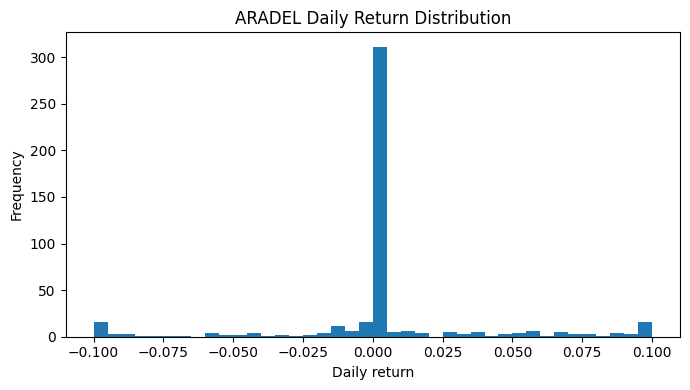

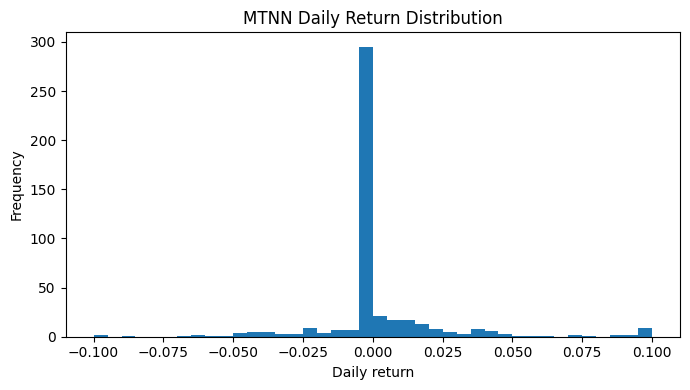

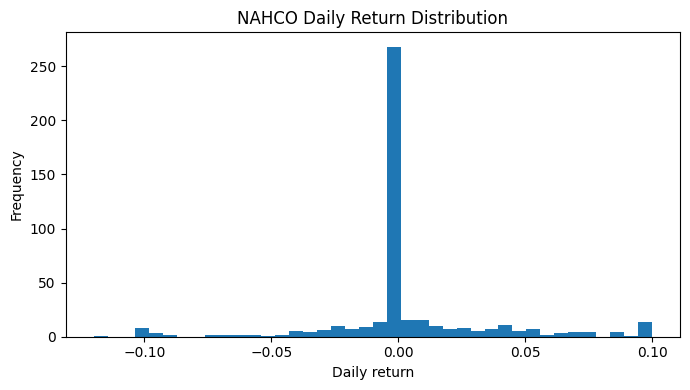

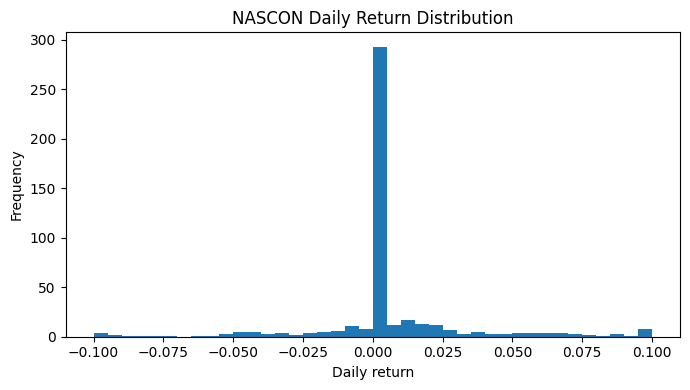

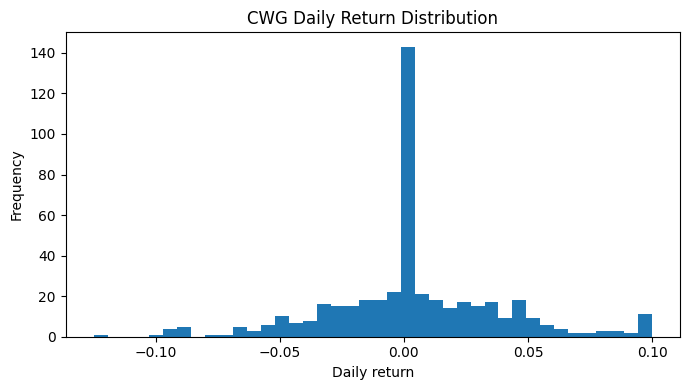

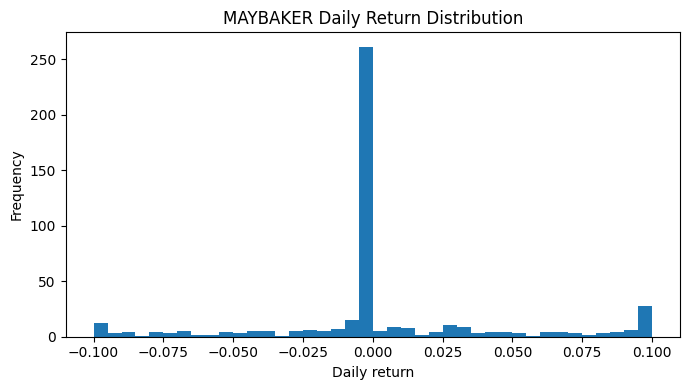

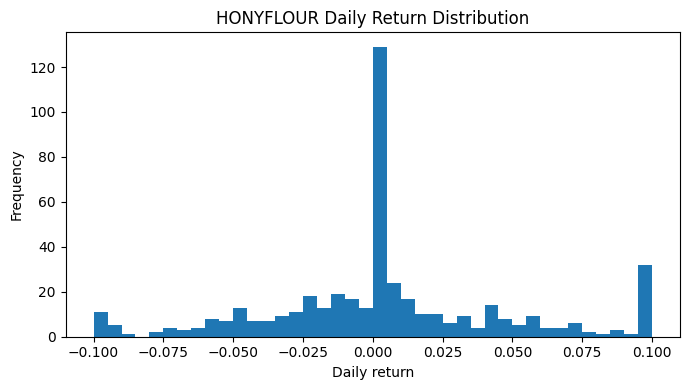

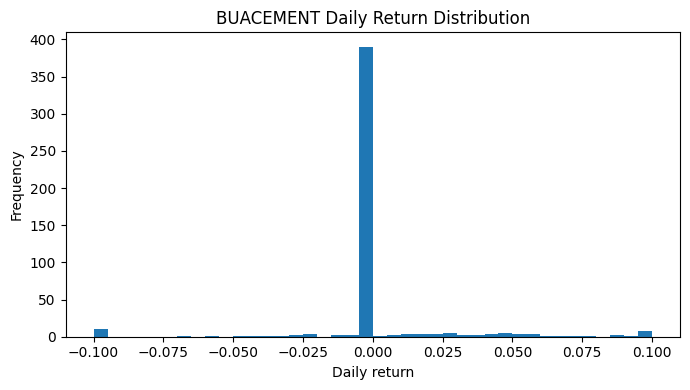

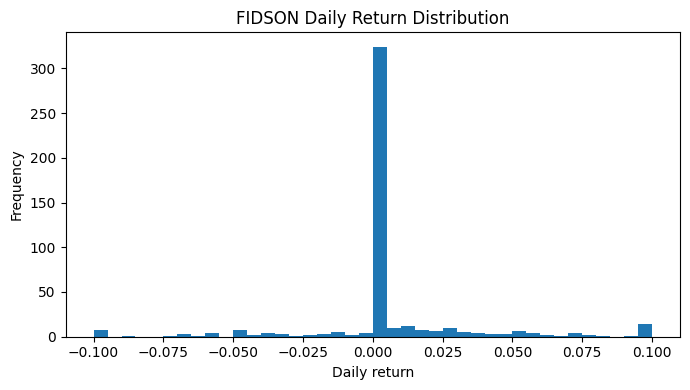

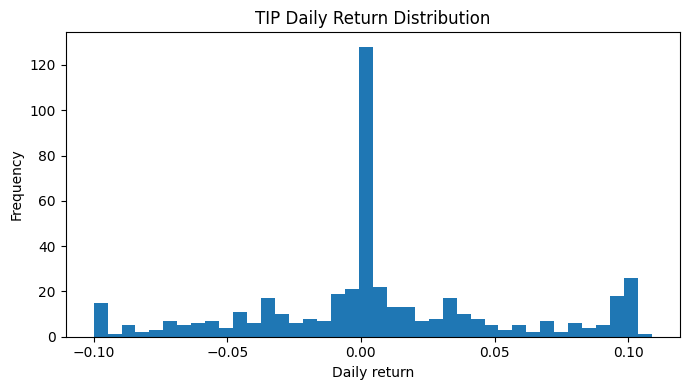

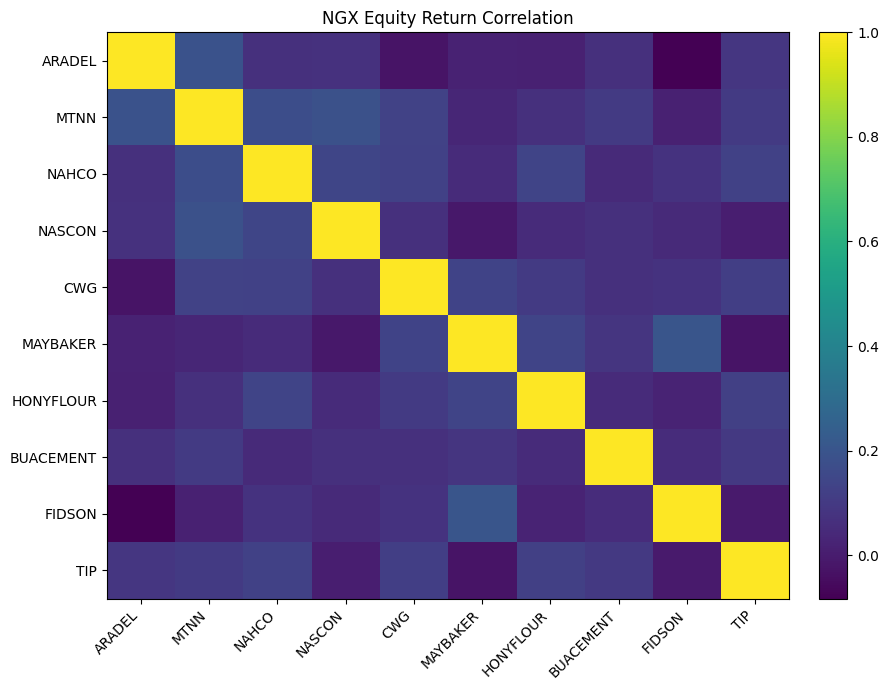

,ADF p-value (Price),ADF p-value (Return)
Ticker,,
ARADEL,0.8574,0.0000
MTNN,0.8794,0.0000
NAHCO,0.5984,0.0000
NASCON,0.7951,0.0000
CWG,0.5713,0.0000
MAYBAKER,0.7633,0.0000
HONYFLOUR,0.1901,0.0000
BUACEMENT,0.7389,0.0000
FIDSON,0.7819,0.0000


In [5]:
returns = prices_assets.pct_change().dropna()
benchmark_returns = asi.pct_change().reindex(returns.index).dropna()
returns = returns.reindex(benchmark_returns.index).dropna()
rf_annual = rf_annual.reindex(returns.index).ffill()

summary_stats = pd.DataFrame({
    "Annual Return": returns.mean() * ANNUALIZATION,
    "Annual Volatility": returns.std() * np.sqrt(ANNUALIZATION),
    "Skewness": returns.skew(),
    "Kurtosis": returns.kurtosis()
}).sort_values("Annual Return", ascending=False)

display(summary_stats)

for ticker in TICKERS:
    plt.figure(figsize=(7, 4))
    plt.hist(returns[ticker].dropna(), bins=40)
    plt.title(f"{ticker} Daily Return Distribution")
    plt.xlabel("Daily return")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

corr = returns.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.index)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("NGX Equity Return Correlation")
plt.tight_layout()
plt.show()

adf_rows = []
for ticker in TICKERS:
    adf_rows.append({
        "Ticker": ticker,
        "ADF p-value (Price)": adfuller(prices_assets[ticker].dropna(), autolag="AIC")[1],
        "ADF p-value (Return)": adfuller(returns[ticker].dropna(), autolag="AIC")[1]
    })

display(pd.DataFrame(adf_rows).set_index("Ticker"))


## 6. EWMA + Ledoit–Wolf covariance risk model

In [6]:
def make_psd(matrix, ridge=RIDGE):
    s = np.asarray(matrix, dtype=float)
    s = (s + s.T) / 2
    eigvals, eigvecs = np.linalg.eigh(s)
    eigvals = np.maximum(eigvals, ridge)
    return eigvecs @ np.diag(eigvals) @ eigvecs.T


def ewma_covariance(ret, lam=EWMA_LAMBDA):
    x = ret.dropna().values
    if len(x) < 2:
        raise ValueError("Not enough observations for EWMA covariance.")
    x = x - np.mean(x, axis=0, keepdims=True)
    s = np.atleast_2d(np.cov(x, rowvar=False))
    for row in x:
        s = lam * s + (1 - lam) * np.outer(row, row)
    return make_psd(s)


def risk_model(ret):
    clean = ret.dropna()
    lw = LedoitWolf().fit(clean.values).covariance_
    ewma = ewma_covariance(clean)
    cov_daily = EWMA_BLEND * ewma + (1 - EWMA_BLEND) * lw
    return make_psd(cov_daily) * ANNUALIZATION


cov_annual = risk_model(returns.loc[IN_SAMPLE_START:IN_SAMPLE_END, TICKERS])
cov_df = pd.DataFrame(cov_annual, index=TICKERS, columns=TICKERS)
vol_table = pd.Series(np.sqrt(np.diag(cov_annual)), index=TICKERS, name="Annual Volatility")

display(cov_df)
display(vol_table.sort_values(ascending=False))


,ARADEL,MTNN,NAHCO,NASCON,CWG,MAYBAKER,HONYFLOUR,BUACEMENT,FIDSON,TIP
ARADEL,0.1940,0.0335,0.0209,0.0196,0.0181,0.0219,0.0271,0.0150,-0.0097,0.0102
MTNN,0.0335,0.1546,0.0420,0.0506,0.0351,0.0240,0.0316,0.0143,-0.0000,0.0191
NAHCO,0.0209,0.0420,0.2298,0.0425,0.0886,0.0042,0.0542,0.0226,0.0008,0.0537
NASCON,0.0196,0.0506,0.0425,0.1788,0.0321,-0.0003,0.0238,0.0149,0.0041,0.0203
CWG,0.0181,0.0351,0.0886,0.0321,0.2607,0.0320,0.0458,0.0250,0.0112,0.0164
MAYBAKER,0.0219,0.0240,0.0042,-0.0003,0.0320,0.3119,0.0842,0.0173,0.0466,-0.0226
HONYFLOUR,0.0271,0.0316,0.0542,0.0238,0.0458,0.0842,0.5109,0.0338,0.0530,0.0822
BUACEMENT,0.0150,0.0143,0.0226,0.0149,0.0250,0.0173,0.0338,0.1129,0.0131,0.0329
FIDSON,-0.0097,-0.0000,0.0008,0.0041,0.0112,0.0466,0.0530,0.0131,0.1663,0.0106
TIP,0.0102,0.0191,0.0537,0.0203,0.0164,-0.0226,0.0822,0.0329,0.0106,0.4251


HONYFLOUR   0.7148
TIP         0.6520
MAYBAKER    0.5585
CWG         0.5106
NAHCO       0.4794
ARADEL      0.4405
NASCON      0.4228
FIDSON      0.4078
MTNN        0.3932
BUACEMENT   0.3360
Name: Annual Volatility, dtype: float64

## 7. NGX market portfolio, risk aversion and equilibrium prior

In [7]:
asi_train = asi.loc[IN_SAMPLE_START:IN_SAMPLE_END].pct_change().dropna()
rf_train = rf_annual.reindex(asi_train.index).ffill()

excess_asi = asi_train - rf_train / ANNUALIZATION
market_excess_ann = excess_asi.mean() * ANNUALIZATION
market_var_ann = asi_train.var() * ANNUALIZATION

delta = market_excess_ann / max(market_var_ann, RIDGE)
delta = float(np.clip(delta, DELTA_FLOOR, DELTA_CAP))

TAU = 1.0 / max(len(returns.loc[IN_SAMPLE_START:IN_SAMPLE_END]), 1)

w_market = w_market.reindex(TICKERS).fillna(0)
w_market = w_market / w_market.sum()

pi_excess = pd.Series(
    delta * cov_annual @ w_market.values,
    index=TICKERS,
    name="pi_excess"
)

market_stats = pd.Series({
    "NGX ASI annual return": asi_train.mean() * ANNUALIZATION,
    "NGX ASI annual volatility": asi_train.std() * np.sqrt(ANNUALIZATION),
    "NGX ASI excess return": market_excess_ann,
    "NGX ASI Sharpe": market_excess_ann / max(np.sqrt(market_var_ann), RIDGE),
    "Calibrated delta": delta,
    "Tau = 1/T": TAU
})

display(market_stats.to_frame("value"))
display(pd.DataFrame({"market_weight": w_market, "pi_excess": pi_excess})
        .sort_values("market_weight", ascending=False))


,value
NGX ASI annual return,0.3906
NGX ASI annual volatility,0.1052
NGX ASI excess return,0.2276
NGX ASI Sharpe,2.1639
Calibrated delta,10.0000
Tau = 1/T,0.0033


,market_weight,pi_excess
MTNN,0.5034,0.8915
BUACEMENT,0.2784,0.4207
ARADEL,0.1816,0.5681
NASCON,0.0128,0.3599
NAHCO,0.0090,0.3418
FIDSON,0.0071,0.0342
HONYFLOUR,0.0039,0.3370
MAYBAKER,0.0018,0.2215
CWG,0.0013,0.2978
TIP,0.0007,0.2202


## 8. Quantitative investor views

The original notebook contained views from a different US-stock universe. This rebuild removes that mismatch. Views are generated from information available up to each rebalance date using 63-day and 126-day momentum, cross-sectional standardisation and a volatility-aware signal. Confidence is bounded to prevent noisy signals from becoming unrealistically strong forecasts.

In [8]:
def zscore_cross_section(series):
    std = series.std(ddof=0)
    if std < 1e-12:
        return pd.Series(0.0, index=series.index)
    return (series - series.mean()) / std


def make_quant_views(ret_window, pi, cov_ann):
    proxy = (1 + ret_window).cumprod()

    fast_n = min(MOMENTUM_FAST, len(proxy) - 1)
    slow_n = min(MOMENTUM_SLOW, len(proxy) - 1)

    mom_fast = proxy.iloc[-1] / proxy.iloc[-fast_n - 1] - 1
    mom_slow = proxy.iloc[-1] / proxy.iloc[-slow_n - 1] - 1

    annual_vol = ret_window.std() * np.sqrt(ANNUALIZATION)
    annual_vol = annual_vol.replace(0, np.nan).fillna(annual_vol.median())

    raw_signal = 0.60 * zscore_cross_section(mom_fast) + 0.40 * zscore_cross_section(mom_slow)
    risk_adjusted = raw_signal / (1 + annual_vol)
    signal = zscore_cross_section(risk_adjusted)

    dispersion = float((ret_window.mean() * ANNUALIZATION).std())
    view_scale = max(0.5 * dispersion * VIEW_SHRINKAGE, 0.01)

    q = (pi + signal * view_scale).clip(-VIEW_MAX_EXCESS, VIEW_MAX_EXCESS)

    confidence = MIN_CONFIDENCE + (
        MAX_CONFIDENCE - MIN_CONFIDENCE
    ) * expit(np.abs(signal) - 0.5)

    return pd.DataFrame({
        "mom_63": mom_fast,
        "mom_126": mom_slow,
        "signal": signal,
        "pi_excess": pi,
        "Q_excess_return": q,
        "confidence": confidence
    })


view_table_is = make_quant_views(
    returns.loc[IN_SAMPLE_START:IN_SAMPLE_END, TICKERS],
    pi_excess,
    cov_annual
)
display(view_table_is.sort_values("signal", ascending=False))


,mom_63,mom_126,signal,pi_excess,Q_excess_return,confidence
BUACEMENT,0.1156,0.8711,1.3456,0.4207,0.2000,0.6348
MTNN,0.1983,0.4179,1.1642,0.8915,0.2000,0.6131
ARADEL,0.2141,0.3215,0.9701,0.5681,0.2000,0.5885
NASCON,0.1082,0.5141,0.3436,0.3599,0.2000,0.5035
MAYBAKER,0.1728,0.2258,0.3189,0.2215,0.2000,0.5002
FIDSON,0.1476,0.1189,-0.1649,0.0342,0.0129,0.4794
CWG,0.0714,0.4229,-0.2667,0.2978,0.2000,0.4931
TIP,-0.0226,0.7162,-0.5282,0.2202,0.1522,0.5289
NAHCO,0.0286,0.1980,-1.2509,0.3418,0.1808,0.6237
HONYFLOUR,-0.0250,-0.0023,-1.9316,0.3370,0.0884,0.6939


## 9. Black–Litterman posterior: P, Q, Ω, μBL and ΣBL

In [9]:
def black_litterman(pi, sigma, tau, q, confidence,
                     extra_P=None, extra_q=None, extra_confidence=None, view_labels=None):
    """
    BL posterior using P = I (one absolute view per asset) and Idzorek-style
    confidence scaling, optionally extended with additional view rows -- e.g.
    portfolio-manager relative/absolute views -- supplied via extra_P/extra_q/
    extra_confidence. Passing none of the extra_* arguments reproduces the
    original identity-only behaviour exactly.
    """
    assets = pi.index
    n = len(assets)

    P = np.eye(n)
    q = pd.Series(q, index=assets).values
    confidence = pd.Series(confidence, index=assets).clip(
        MIN_CONFIDENCE, MAX_CONFIDENCE
    ).values

    if extra_P is not None and len(extra_P) > 0:
        extra_P = np.asarray(extra_P, dtype=float)
        extra_q = np.asarray(extra_q, dtype=float)
        extra_confidence = np.clip(
            np.asarray(extra_confidence, dtype=float), MIN_CONFIDENCE, MAX_CONFIDENCE
        )
        P = np.vstack([P, extra_P])
        q = np.concatenate([q, extra_q])
        confidence = np.concatenate([confidence, extra_confidence])

    if view_labels is None:
        view_labels = list(assets)

    sigma = make_psd(sigma)
    tau_sigma = tau * sigma

    base_omega = np.diag(P @ tau_sigma @ P.T)
    omega_diag = base_omega * (1 - confidence) / confidence
    omega_diag = np.maximum(omega_diag, RIDGE)
    Omega = np.diag(omega_diag)

    inv_tau_sigma = np.linalg.pinv(make_psd(tau_sigma))
    inv_omega = np.linalg.pinv(Omega)

    posterior_precision = inv_tau_sigma + P.T @ inv_omega @ P
    posterior_cov = np.linalg.pinv(make_psd(posterior_precision))

    posterior_mean = posterior_cov @ (
        inv_tau_sigma @ pi.values + P.T @ inv_omega @ q
    )

    return (
        pd.Series(posterior_mean, index=assets, name="mu_BL"),
        pd.DataFrame(posterior_cov, index=assets, columns=assets),
        P,
        pd.DataFrame(Omega, index=view_labels, columns=view_labels)
    )


mu_bl, sigma_bl, P, Omega = black_litterman(
    pi_excess, cov_annual, TAU,
    view_table_is["Q_excess_return"],
    view_table_is["confidence"]
)

bl_table = pd.DataFrame({
    "Market Weight": w_market,
    "Equilibrium Excess Return": pi_excess,
    "BL Posterior Excess Return": mu_bl,
    "View": view_table_is["Q_excess_return"],
    "Confidence": view_table_is["confidence"]
})

display(bl_table.sort_values("BL Posterior Excess Return", ascending=False))

print("P matrix:")
display(pd.DataFrame(P, index=TICKERS, columns=TICKERS))

print("Omega diagonal:")
display(pd.Series(np.diag(Omega), index=TICKERS, name="view_variance"))

print("Posterior covariance:")
display(sigma_bl)


,Market Weight,Equilibrium Excess Return,BL Posterior Excess Return,View,Confidence
MTNN,0.5034,0.8915,0.4518,0.2000,0.6131
ARADEL,0.1816,0.5681,0.3100,0.2000,0.5885
BUACEMENT,0.2784,0.4207,0.2622,0.2000,0.6348
NASCON,0.0128,0.3599,0.1983,0.2000,0.5035
NAHCO,0.0090,0.3418,0.1863,0.1808,0.6237
CWG,0.0013,0.2978,0.1810,0.2000,0.4931
MAYBAKER,0.0018,0.2215,0.1548,0.2000,0.5002
TIP,0.0007,0.2202,0.1334,0.1522,0.5289
HONYFLOUR,0.0039,0.3370,0.1275,0.0884,0.6939
FIDSON,0.0071,0.0342,0.0210,0.0129,0.4794


P matrix:


,ARADEL,MTNN,NAHCO,NASCON,CWG,MAYBAKER,HONYFLOUR,BUACEMENT,FIDSON,TIP
ARADEL,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
MTNN,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
NAHCO,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
NASCON,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
CWG,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
MAYBAKER,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000
HONYFLOUR,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000
BUACEMENT,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
FIDSON,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
TIP,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000


Omega diagonal:


ARADEL      0.0005
MTNN        0.0003
NAHCO       0.0005
NASCON      0.0006
CWG         0.0009
MAYBAKER    0.0010
HONYFLOUR   0.0008
BUACEMENT   0.0002
FIDSON      0.0006
TIP         0.0013
Name: view_variance, dtype: float64

Posterior covariance:


,ARADEL,MTNN,NAHCO,NASCON,CWG,MAYBAKER,HONYFLOUR,BUACEMENT,FIDSON,TIP
ARADEL,0.0003,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000
MTNN,0.0000,0.0002,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000
NAHCO,0.0000,0.0000,0.0003,0.0000,0.0001,-0.0000,0.0000,0.0000,-0.0000,0.0000
NASCON,0.0000,0.0000,0.0000,0.0003,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
CWG,0.0000,0.0000,0.0001,0.0000,0.0004,0.0000,0.0000,0.0000,0.0000,-0.0000
MAYBAKER,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0005,0.0000,0.0000,0.0000,-0.0000
HONYFLOUR,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0005,0.0000,0.0000,0.0000
BUACEMENT,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0000,0.0000
FIDSON,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0003,0.0000
TIP,0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0007


## 10. Long-only constrained portfolio optimisation

In [10]:
def portfolio_vol(w, sigma):
    return float(np.sqrt(max(w @ sigma @ w, 0)))


def optimise_portfolio(mu, sigma, benchmark_w, previous_w=None, risk_aversion=None):
    """Optimise BL expected utility with practical portfolio constraints."""
    assets = mu.index
    n = len(assets)
    mu_v = mu.values
    sigma_m = make_psd(sigma.values if isinstance(sigma, pd.DataFrame) else sigma)
    bench = benchmark_w.reindex(assets).fillna(0).values

    if previous_w is None:
        previous_w = benchmark_w.copy()
    prev = previous_w.reindex(assets).fillna(0).values
    d = float(delta if risk_aversion is None else risk_aversion)

    def objective(w):
        utility = w @ mu_v - 0.5 * d * (w @ sigma_m @ w)
        turnover = np.sum(np.abs(w - prev))
        return -(utility - TURNOVER_PENALTY * turnover)

    bounds = []
    for b in bench:
        lo = max(0.0, b - MAX_ACTIVE_WEIGHT)
        hi = min(MAX_WEIGHT, b + MAX_ACTIVE_WEIGHT)
        # If a benchmark weight itself exceeds MAX_WEIGHT + MAX_ACTIVE_WEIGHT,
        # the two constraints cannot both be satisfied. Relax the active-weight
        # bound for that asset rather than creating an invalid/infeasible box.
        if lo > hi:
            lo, hi = 0.0, MAX_WEIGHT
        bounds.append((lo, hi))

    constraints = [
        {"type": "eq", "fun": lambda w: np.sum(w) - 1.0},
        {"type": "ineq", "fun": lambda w: MAX_TURNOVER - np.sum(np.abs(w - prev))},
        {"type": "ineq", "fun": lambda w: MAX_PORTFOLIO_VOL - portfolio_vol(w, sigma_m)}
    ]

    if SECTOR_MAP:
        sectors = sorted(set(SECTOR_MAP.get(a, "OTHER") for a in assets))
        for sector in sectors:
            idx = [i for i, a in enumerate(assets) if SECTOR_MAP.get(a, "OTHER") == sector]
            constraints.append({
                "type": "ineq",
                "fun": lambda w, idx=idx: MAX_SECTOR_WEIGHT - np.sum(w[idx])
            })

    x0 = prev.copy()
    if not np.isclose(x0.sum(), 1):
        x0 = np.repeat(1 / n, n)

    result = minimize(
        objective, x0=x0, method="SLSQP",
        bounds=bounds, constraints=constraints,
        options={"maxiter": 2000, "ftol": 1e-10}
    )

    if result.success:
        return pd.Series(result.x, index=assets, name="weight"), result.message

    # Robust fallback: minimum-variance fully invested solution.
    fallback = minimize(
        lambda w: portfolio_vol(w, sigma_m),
        x0=np.repeat(1 / n, n),
        method="SLSQP",
        bounds=[(0, MAX_WEIGHT)] * n,
        constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}],
        options={"maxiter": 2000}
    )

    if not fallback.success:
        raise RuntimeError(f"Optimisation failed: {result.message}")

    return pd.Series(fallback.x, index=assets), f"Fallback minimum-variance: {fallback.message}"


bl_weights, opt_status = optimise_portfolio(mu_bl, cov_df, w_market, w_market)

print(opt_status)
comparison = pd.DataFrame({
    "Market Cap Proxy": w_market,
    "BL Constrained": bl_weights
})
comparison["Active Weight"] = comparison["BL Constrained"] - comparison["Market Cap Proxy"]
display(comparison.sort_values("BL Constrained", ascending=False))


Fallback minimum-variance: Optimization terminated successfully


,Market Cap Proxy,BL Constrained,Active Weight
BUACEMENT,0.2784,0.2000,-0.0784
FIDSON,0.0071,0.1986,0.1915
ARADEL,0.1816,0.1414,-0.0402
MTNN,0.5034,0.1198,-0.3836
NASCON,0.0128,0.1179,0.1052
MAYBAKER,0.0018,0.0624,0.0606
NAHCO,0.0090,0.0601,0.0511
TIP,0.0007,0.0503,0.0496
CWG,0.0013,0.0495,0.0482
HONYFLOUR,0.0039,0.0000,-0.0039


## 11. Risk attribution

In [11]:
def risk_contribution(weights, sigma):
    w = weights.values if isinstance(weights, pd.Series) else np.asarray(weights)
    S = sigma.values if isinstance(sigma, pd.DataFrame) else np.asarray(sigma)
    pv = np.sqrt(max(w @ S @ w, RIDGE))
    contribution = w * (S @ w) / pv
    return pd.Series(contribution / max(pv, RIDGE), index=weights.index)


rc = risk_contribution(bl_weights, cov_df)
diagnostics = pd.DataFrame({
    "Weight": bl_weights,
    "Risk Contribution": rc,
    "Annual Volatility": vol_table.reindex(bl_weights.index)
})
display(diagnostics.sort_values("Weight", ascending=False))

print(f"Expected annual excess return: {bl_weights @ mu_bl:.2%}")
print(f"Expected annual volatility:     {portfolio_vol(bl_weights.values, cov_df.values):.2%}")
print(f"Expected Sharpe proxy:          {(bl_weights @ mu_bl) / max(portfolio_vol(bl_weights.values, cov_df.values), RIDGE):.2f}")
print(f"One-way turnover vs market proxy: {np.abs(bl_weights - w_market).sum():.2%}")


,Weight,Risk Contribution,Annual Volatility
BUACEMENT,0.2000,0.1886,0.3360
FIDSON,0.1986,0.2014,0.4078
ARADEL,0.1414,0.1435,0.4405
MTNN,0.1198,0.1214,0.3932
NASCON,0.1179,0.1197,0.4228
MAYBAKER,0.0624,0.0633,0.5585
NAHCO,0.0601,0.0609,0.4794
TIP,0.0503,0.0510,0.6520
CWG,0.0495,0.0502,0.5106
HONYFLOUR,0.0000,0.0000,0.7148


Expected annual excess return: 21.45%
Expected annual volatility:     19.56%
Expected Sharpe proxy:          1.10
One-way turnover vs market proxy: 101.22%


## 12. Walk-forward OOS engine

Every rebalance uses only observations strictly before that date. The covariance model, risk aversion, quantitative views and BL posterior are all re-estimated. Transaction costs are charged when the portfolio changes. This is the core upgrade from a static in-sample BL allocation.

In [12]:
def calibrate_delta(asi_ret, rf_ann):
    rf_daily = rf_ann.reindex(asi_ret.index).ffill() / ANNUALIZATION
    excess = asi_ret - rf_daily
    d = (excess.mean() * ANNUALIZATION) / max(
        asi_ret.var() * ANNUALIZATION, RIDGE
    )
    return float(np.clip(d, DELTA_FLOOR, DELTA_CAP))


def compute_walkforward(oos_returns, benchmark_ret, full_returns, rf_ann):
    dates = oos_returns.index
    rebalance_dates = list(dates[::REBALANCE_DAYS])

    portfolio_returns = pd.Series(index=dates, dtype=float)
    benchmark_returns = benchmark_ret.reindex(dates).copy()

    weights_history = []
    records = []
    previous_w = w_market.copy()

    for i, date in enumerate(rebalance_dates):
        prior = full_returns.loc[full_returns.index < date].tail(LOOKBACK_DAYS)
        stock_prior = prior[TICKERS].dropna()

        if len(stock_prior) < LOOKBACK_DAYS:
            continue

        sigma = pd.DataFrame(
            risk_model(stock_prior),
            index=TICKERS, columns=TICKERS
        )

        asi_prior = asi.loc[asi.index < date].pct_change().dropna().tail(LOOKBACK_DAYS)
        rf_prior = rf_ann.loc[rf_ann.index < date].tail(LOOKBACK_DAYS)
        rf_prior = rf_prior.reindex(asi_prior.index).ffill()

        d = calibrate_delta(asi_prior, rf_prior)
        market_w = w_market.reindex(TICKERS).fillna(0)
        pi = pd.Series(d * sigma.values @ market_w.values, index=TICKERS)

        tau = 1.0 / len(stock_prior)
        views = make_quant_views(stock_prior, pi, sigma.values)

        mu, sigma_bl, P, Omega = black_litterman(
            pi, sigma.values, tau,
            views["Q_excess_return"],
            views["confidence"]
        )

        weights, status = optimise_portfolio(
            mu, sigma, market_w, previous_w=previous_w,
            risk_aversion=d
        )

        next_date = rebalance_dates[i + 1] if i + 1 < len(rebalance_dates) else dates.max()
        segment = oos_returns.loc[date:next_date, TICKERS]

        if segment.empty:
            continue

        turnover = float(np.abs(weights - previous_w).sum())
        tc = turnover * TRANSACTION_COST_BPS / 10000.0

        seg_port = segment @ weights
        seg_port.iloc[0] -= tc
        portfolio_returns.loc[seg_port.index] = seg_port

        weights_history.append(pd.DataFrame([weights.values], index=[date], columns=TICKERS))
        records.append({
            "date": date,
            "delta": d,
            "tau": tau,
            "turnover": turnover,
            "transaction_cost": tc,
            "expected_return": float(weights @ mu),
            "expected_vol": portfolio_vol(weights, sigma),
            "optimiser_status": status
        })

        previous_w = weights.copy()

    weights_history = (
        pd.concat(weights_history)
        if weights_history else pd.DataFrame(columns=TICKERS)
    )
    records = (
        pd.DataFrame(records).set_index("date")
        if records else pd.DataFrame()
    )

    return portfolio_returns.dropna(), benchmark_returns.dropna(), weights_history, records


# Synthetic residual return makes the ASI identity explicit:
# R_ASI = sum(w_i R_i) + w_rest R_rest.
selected_contribution = returns[TICKERS].mul(w_market, axis=1).sum(axis=1)
rest_weight = max(1.0 - float(w_market.sum()), 0.0)

if rest_weight > 1e-8:
    rest_return = (benchmark_returns - selected_contribution) / rest_weight
else:
    rest_return = pd.Series(0.0, index=returns.index)

full_returns = returns[TICKERS].copy()
full_returns[REST_ASSET] = rest_return

oos_returns = returns.loc[OOS_START:OOS_END, TICKERS]
oos_benchmark = benchmark_returns.loc[OOS_START:OOS_END]

oos_bl, oos_asi, wf_weights, wf_log = compute_walkforward(
    oos_returns, oos_benchmark, full_returns, rf_annual
)

display(wf_log)
display(wf_weights.tail())


,delta,tau,turnover,transaction_cost,expected_return,expected_vol,optimiser_status
date,,,,,,,
2026-01-02,10.0000,0.0040,0.9673,0.0048,0.2213,0.1934,Fallback minimum-variance: Optimization termin...
2026-02-02,10.0000,0.0040,0.3065,0.0015,0.2670,0.1941,Optimization terminated successfully
2026-03-03,10.0000,0.0040,0.2279,0.0011,0.3471,0.2427,Optimization terminated successfully
2026-04-07,10.0000,0.0040,0.2293,0.0011,0.3178,0.2196,Optimization terminated successfully
2026-05-07,10.0000,0.0040,0.2519,0.0013,0.3292,0.2437,Optimization terminated successfully
2026-06-09,10.0000,0.0040,0.1803,0.0009,0.3176,0.2315,Optimization terminated successfully
2026-07-09,10.0000,0.0040,0.1227,0.0006,0.3368,0.2272,Optimization terminated successfully
2026-08-07,10.0000,0.0040,0.1016,0.0005,0.2642,0.2095,Optimization terminated successfully
2026-09-08,10.0000,0.0040,0.2561,0.0013,0.2376,0.1993,Optimization terminated successfully


,ARADEL,MTNN,NAHCO,NASCON,CWG,MAYBAKER,HONYFLOUR,BUACEMENT,FIDSON,TIP
2026-05-07,0.1275,0.2000,0.0480,0.1064,0.0653,0.0422,0.0841,0.1985,0.1281,0.0000
2026-06-09,0.1508,0.2000,0.0597,0.1305,0.0450,0.0409,0.0498,0.2000,0.0938,0.0295
2026-07-09,0.1204,0.2000,0.0723,0.1234,0.0660,0.0623,0.0562,0.2000,0.0938,0.0056
2026-08-07,0.1712,0.2000,0.0501,0.1042,0.0617,0.0580,0.0554,0.2000,0.0938,0.0056
2026-09-08,0.1377,0.2000,0.0945,0.0714,0.0617,0.0967,0.0749,0.2000,0.0320,0.0311


## 13. OOS benchmarks and performance metrics

In [13]:
def performance_metrics(ret, rf_ann=None):
    ret = pd.Series(ret).dropna()
    if ret.empty:
        return pd.Series(dtype=float)

    growth = (1 + ret).cumprod()
    total_return = growth.iloc[-1] - 1
    ann_return = growth.iloc[-1] ** (ANNUALIZATION / len(ret)) - 1
    ann_vol = ret.std() * np.sqrt(ANNUALIZATION)

    if rf_ann is not None:
        rf_daily = pd.Series(rf_ann).reindex(ret.index).ffill() / ANNUALIZATION
        excess = ret - rf_daily
    else:
        excess = ret

    sharpe = excess.mean() / max(excess.std(), RIDGE) * np.sqrt(ANNUALIZATION)
    downside = ret[ret < 0].std() * np.sqrt(ANNUALIZATION)
    sortino = excess.mean() * ANNUALIZATION / max(downside, RIDGE)

    dd = growth / growth.cummax() - 1
    max_dd = dd.min()
    calmar = ann_return / abs(max_dd) if max_dd < 0 else np.nan

    return pd.Series({
        "Total Return": total_return,
        "Annualised Return": ann_return,
        "Annualised Volatility": ann_vol,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max Drawdown": max_dd,
        "Calmar": calmar
    })


ew_weights = pd.Series(1 / len(TICKERS), index=TICKERS)
ew_oos = oos_returns @ ew_weights
mc_oos = oos_returns @ w_market

performance = pd.DataFrame({
    "BL Walk-Forward": performance_metrics(oos_bl, rf_annual.loc[oos_bl.index]),
    "Market-Cap Proxy": performance_metrics(mc_oos, rf_annual.loc[mc_oos.index]),
    "Equal Weight": performance_metrics(ew_oos, rf_annual.loc[ew_oos.index]),
    "NGX ASI": performance_metrics(oos_asi, rf_annual.loc[oos_asi.index])
})

display(performance)


,BL Walk-Forward,Market-Cap Proxy,Equal Weight,NGX ASI
Total Return,0.8401,0.7646,0.6458,0.5566
Annualised Return,1.4694,1.3207,1.0929,0.9269
Annualised Volatility,0.2496,0.3035,0.2309,0.1497
Sharpe,3.0979,2.3909,2.6114,3.3717
Sortino,6.7870,3.6890,5.8763,6.6744
Max Drawdown,-0.2133,-0.2264,-0.2171,-0.1116
Calmar,6.8887,5.8332,5.0332,8.3039


## 14. Cumulative performance, drawdown, rolling volatility and weights

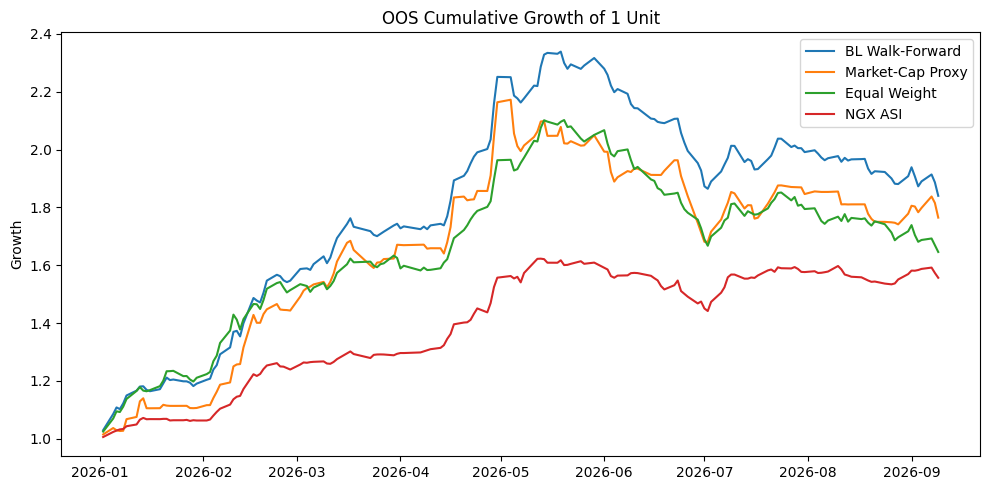

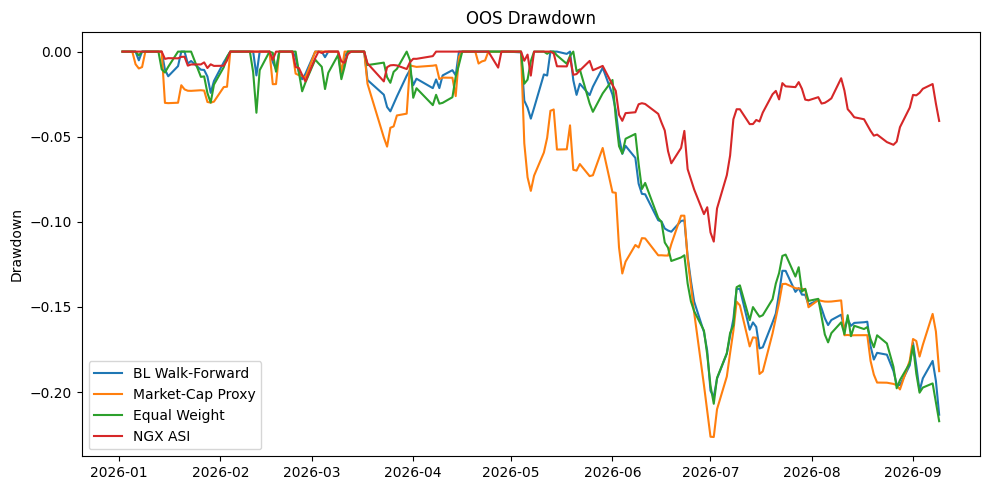

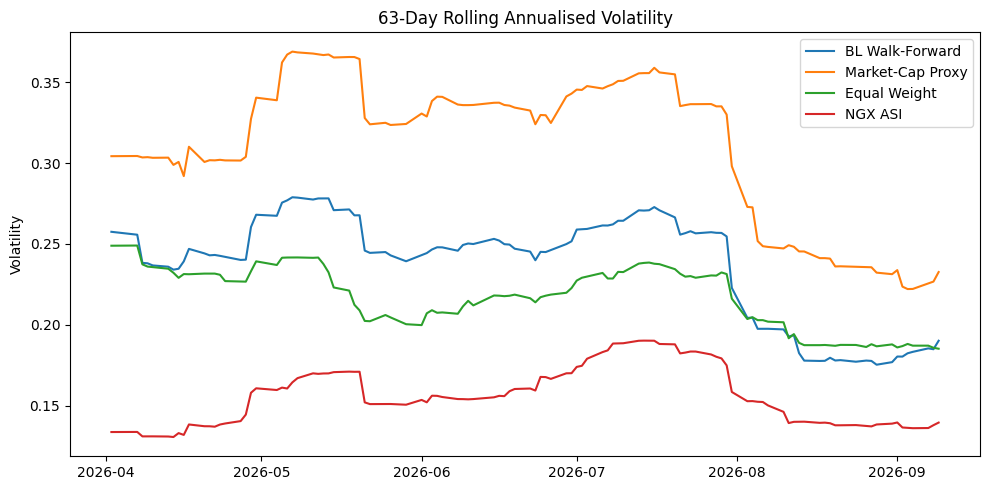

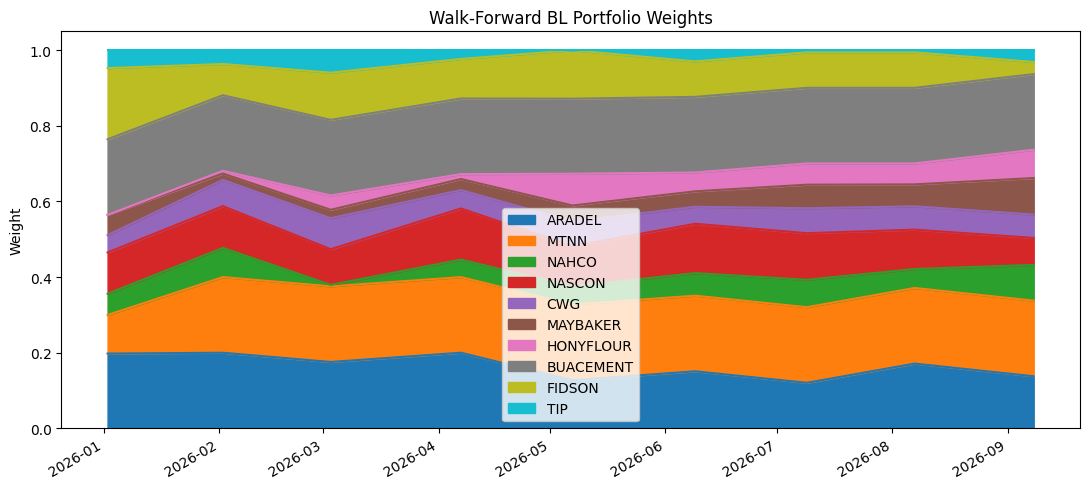

In [14]:
strategy_returns = pd.DataFrame({
    "BL Walk-Forward": oos_bl,
    "Market-Cap Proxy": mc_oos,
    "Equal Weight": ew_oos,
    "NGX ASI": oos_asi
}).dropna(how="all")

growth = (1 + strategy_returns.fillna(0)).cumprod()

plt.figure(figsize=(10, 5))
for name in growth.columns:
    plt.plot(growth.index, growth[name], label=name)
plt.title("OOS Cumulative Growth of 1 Unit")
plt.ylabel("Growth")
plt.legend()
plt.tight_layout()
plt.show()

drawdowns = growth / growth.cummax() - 1
plt.figure(figsize=(10, 5))
for name in drawdowns.columns:
    plt.plot(drawdowns.index, drawdowns[name], label=name)
plt.title("OOS Drawdown")
plt.ylabel("Drawdown")
plt.legend()
plt.tight_layout()
plt.show()

rolling_vol = strategy_returns.rolling(63).std() * np.sqrt(ANNUALIZATION)
plt.figure(figsize=(10, 5))
for name in rolling_vol.columns:
    plt.plot(rolling_vol.index, rolling_vol[name], label=name)
plt.title("63-Day Rolling Annualised Volatility")
plt.ylabel("Volatility")
plt.legend()
plt.tight_layout()
plt.show()

if not wf_weights.empty:
    ax = wf_weights.plot.area(figsize=(11, 5), stacked=True)
    ax.set_title("Walk-Forward BL Portfolio Weights")
    ax.set_ylabel("Weight")
    plt.tight_layout()
    plt.show()


## 15. Active risk, tracking error and turnover

In [15]:
if not oos_bl.empty and not oos_asi.empty:
    active = oos_bl.reindex(oos_asi.index) - oos_asi
    tracking_error = active.std() * np.sqrt(ANNUALIZATION)
    information_ratio = active.mean() / max(active.std(), RIDGE) * np.sqrt(ANNUALIZATION)
else:
    tracking_error = np.nan
    information_ratio = np.nan

active_metrics = pd.Series({
    "Tracking Error vs ASI": tracking_error,
    "Information Ratio vs ASI": information_ratio,
    "Total One-Way Turnover": wf_log["turnover"].sum() if not wf_log.empty else np.nan,
    "Average Rebalance Turnover": wf_log["turnover"].mean() if not wf_log.empty else np.nan
})

display(active_metrics.to_frame("value"))
if not wf_log.empty:
    display(wf_log[["turnover", "transaction_cost", "expected_return", "expected_vol"]])


,value
Tracking Error vs ASI,0.1698
Information Ratio vs ASI,1.5801
Total One-Way Turnover,2.6436
Average Rebalance Turnover,0.2937


,turnover,transaction_cost,expected_return,expected_vol
date,,,,
2026-01-02,0.9673,0.0048,0.2213,0.1934
2026-02-02,0.3065,0.0015,0.2670,0.1941
2026-03-03,0.2279,0.0011,0.3471,0.2427
2026-04-07,0.2293,0.0011,0.3178,0.2196
2026-05-07,0.2519,0.0013,0.3292,0.2437
2026-06-09,0.1803,0.0009,0.3176,0.2315
2026-07-09,0.1227,0.0006,0.3368,0.2272
2026-08-07,0.1016,0.0005,0.2642,0.2095
2026-09-08,0.2561,0.0013,0.2376,0.1993


## 16. Stress testing

In [16]:
latest_weights = (
    wf_weights.iloc[-1].reindex(TICKERS).fillna(0)
    if not wf_weights.empty else bl_weights.copy()
)
latest_cov = cov_df.reindex(index=TICKERS, columns=TICKERS)
base_vol = portfolio_vol(latest_weights, latest_cov)

stress = pd.Series({
    "Market -10%": -0.10 * latest_weights.sum(),
    "Market -20%": -0.20 * latest_weights.sum(),
    "Market +10%":  0.10 * latest_weights.sum(),
    "Volatility +25% (estimated vol)": base_vol * 1.25,
    "Volatility -25% (estimated vol)": base_vol * 0.75
}, name="Scenario value")

display(stress.to_frame())
print(f"Base estimated annual volatility: {base_vol:.2%}")


,Scenario value
Market -10%,-0.1000
Market -20%,-0.2000
Market +10%,0.1000
Volatility +25% (estimated vol),0.2722
Volatility -25% (estimated vol),0.1633


Base estimated annual volatility: 21.77%


## 17. Sensitivity analysis

In [17]:
tau_rows = []

for mult in [0.5, 1.0, 2.0]:
    mu_test, _, _, _ = black_litterman(
        pi_excess, cov_annual, TAU * mult,
        view_table_is["Q_excess_return"],
        view_table_is["confidence"]
    )
    test_w, _ = optimise_portfolio(mu_test, cov_df, w_market, w_market)
    tau_rows.append(pd.Series(test_w, name=f"tau x {mult:.1f}"))

display(pd.DataFrame(tau_rows))

conf_results = {}
for mult in [0.75, 1.00, 1.25]:
    conf = (view_table_is["confidence"] * mult).clip(
        MIN_CONFIDENCE, MAX_CONFIDENCE
    )
    mu_test, _, _, _ = black_litterman(
        pi_excess, cov_annual, TAU,
        view_table_is["Q_excess_return"], conf
    )
    test_w, _ = optimise_portfolio(mu_test, cov_df, w_market, w_market)
    conf_results[f"confidence x {mult:.2f}"] = test_w

display(pd.DataFrame(conf_results))


,ARADEL,MTNN,NAHCO,NASCON,CWG,MAYBAKER,HONYFLOUR,BUACEMENT,FIDSON,TIP
tau x 0.5,0.1414,0.1198,0.0601,0.1179,0.0495,0.0624,0.0000,0.2000,0.1986,0.0503
tau x 1.0,0.1414,0.1198,0.0601,0.1179,0.0495,0.0624,0.0000,0.2000,0.1986,0.0503
tau x 2.0,0.1414,0.1198,0.0601,0.1179,0.0495,0.0624,0.0000,0.2000,0.1986,0.0503


,confidence x 0.75,confidence x 1.00,confidence x 1.25
ARADEL,0.1414,0.1414,0.1414
MTNN,0.1198,0.1198,0.1198
NAHCO,0.0601,0.0601,0.0601
NASCON,0.1179,0.1179,0.1179
CWG,0.0495,0.0495,0.0495
MAYBAKER,0.0624,0.0624,0.0624
HONYFLOUR,0.0000,0.0000,0.0000
BUACEMENT,0.2000,0.2000,0.2000
FIDSON,0.1986,0.1986,0.1986
TIP,0.0503,0.0503,0.0503


## 18A — Portfolio manager views

This section lets the portfolio manager inject their own explicit views into the **final** Black-Litterman portfolio construction below (Section 18B), on top of the purely quantitative momentum-based views from Section 13.

Two view types are supported, matching standard Black-Litterman practice:

- **Absolute view**: "Ticker X will deliver an annualised excess return of Y%."
- **Relative view**: "Basket A will outperform Basket B by Y%" (equal-weighted within each leg).

Each view also carries a **confidence** in (0, 1) -- higher confidence pulls the posterior further from the quantitative/equilibrium estimate toward the manager's stated view, following the same Idzorek-style scaling already used for the quantitative views.

**Leave `MANAGER_VIEWS = []` to run the model exactly as before (quantitative views only).** The example views below are illustrative placeholders for the actual NGX universe -- replace them with real convictions before using this for a live allocation decision.


In [18]:
# ------------------------------------------------------------------
# Portfolio manager views
# ------------------------------------------------------------------
# Each view is a dict with:
#   "type"        : "absolute" or "relative"
#   "view"        : annualised excess-return magnitude of the view (e.g. 0.15 = 15%)
#   "confidence"  : manager's confidence in the view, in (0, 1)
#   "ticker"      : required for "absolute" views
#   "long"/"short": required for "relative" views -- lists of tickers (equal-weighted per leg)
#   "label"       : optional short name used only for display
#
# EXAMPLE / ILLUSTRATIVE -- replace with the manager's actual convictions before live use.
MANAGER_VIEWS = [
    {
        "type": "absolute",
        "ticker": "ARADEL",
        "view": 0.50,
        "confidence": 0.65,
        "label": "ARADEL absolute (oil & gas growth thesis)"
    },
    {
        "type": "absolute",
        "ticker": "BUACEMENT",
        "view": 0.15,
        "confidence": 0.55,
        "label": "BUACEMENT absolute (stable cement demand)"
    },
    {
        "type": "relative",
        "long": ["MTNN"],
        "short": ["CWG"],
        "view": 0.10,
        "confidence": 0.50,
        "label": "MTNN vs CWG (large-cap defensive over small-cap tech)"
    },
    {
        "type": "relative",
        "long": ["FIDSON", "MAYBAKER"],
        "short": ["HONYFLOUR"],
        "view": 0.06,
        "confidence": 0.45,
        "label": "Pharma basket vs HONYFLOUR"
    },
]
# To run with quantitative views only, set:
# MANAGER_VIEWS = []


def build_manager_view_matrix(manager_views, tickers):
    """
    Convert a list of portfolio-manager view dicts into Black-Litterman P/Q/confidence rows.

    Returns (None, None, None, []) if manager_views is empty, so downstream code can
    pass the result straight through to black_litterman()'s extra_P/extra_q/extra_confidence
    arguments without any special-casing.
    """
    n = len(tickers)
    idx = {t: i for i, t in enumerate(tickers)}
    rows, qs, confs, labels = [], [], [], []

    for v in manager_views:
        row = np.zeros(n)
        vtype = v.get("type", "absolute")

        if vtype == "absolute":
            t = v["ticker"]
            if t not in idx:
                raise ValueError(f"Manager view ticker '{t}' not found in TICKERS: {tickers}")
            row[idx[t]] = 1.0
            default_label = f"{t} absolute"

        elif vtype == "relative":
            long_legs, short_legs = v["long"], v["short"]
            for t in long_legs:
                if t not in idx:
                    raise ValueError(f"Manager view ticker '{t}' not found in TICKERS: {tickers}")
                row[idx[t]] += 1.0 / len(long_legs)
            for t in short_legs:
                if t not in idx:
                    raise ValueError(f"Manager view ticker '{t}' not found in TICKERS: {tickers}")
                row[idx[t]] -= 1.0 / len(short_legs)
            default_label = f"{'+'.join(long_legs)} vs {'+'.join(short_legs)}"

        else:
            raise ValueError(f"Unknown manager view type: {vtype!r} (use 'absolute' or 'relative')")

        if not (0.0 < v["confidence"] < 1.0):
            raise ValueError(f"Manager view confidence must be in (0, 1): got {v['confidence']}")

        rows.append(row)
        qs.append(float(v["view"]))
        confs.append(float(v["confidence"]))
        labels.append(v.get("label", default_label))

    if not rows:
        return None, None, None, []

    return np.vstack(rows), np.array(qs), np.array(confs), labels


# Preview: show the manager views as an explicit P/Q/confidence table before they are applied.
_preview_P, _preview_q, _preview_conf, _preview_labels = build_manager_view_matrix(MANAGER_VIEWS, TICKERS)
if _preview_P is not None:
    print(f"{len(MANAGER_VIEWS)} portfolio manager view(s) configured:\n")
    display(pd.DataFrame(_preview_P, index=_preview_labels, columns=TICKERS).style.format("{:+.2f}"))
    display(pd.DataFrame({
        "View (annualised excess return)": _preview_q,
        "Confidence": _preview_conf
    }, index=_preview_labels).style.format({
        "View (annualised excess return)": "{:+.2%}",
        "Confidence": "{:.0%}"
    }))
else:
    print("MANAGER_VIEWS is empty -- the final portfolio construction below will use "
          "purely quantitative views, identical to the original model.")


4 portfolio manager view(s) configured:



,ARADEL,MTNN,NAHCO,NASCON,CWG,MAYBAKER,HONYFLOUR,BUACEMENT,FIDSON,TIP
ARADEL absolute (oil & gas growth thesis),+1.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00
BUACEMENT absolute (stable cement demand),+0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+0.00,+1.00,+0.00,+0.00
MTNN vs CWG (large-cap defensive over small-cap tech),+0.00,+1.00,+0.00,+0.00,-1.00,+0.00,+0.00,+0.00,+0.00,+0.00
Pharma basket vs HONYFLOUR,+0.00,+0.00,+0.00,+0.00,+0.00,+0.50,-1.00,+0.00,+0.50,+0.00


,View (annualised excess return),Confidence
ARADEL absolute (oil & gas growth thesis),+50.00%,65%
BUACEMENT absolute (stable cement demand),+15.00%,55%
MTNN vs CWG (large-cap defensive over small-cap tech),+10.00%,50%
Pharma basket vs HONYFLOUR,+6.00%,45%


## 18B — Point-in-Time Recommended Portfolio Engine

This section produces a **model allocation snapshot** for either the latest available date or a user-selected historical date.

- `MODEL_MODE = "CURRENT"` → latest common trading date in the downloaded data.
- `MODEL_MODE = "HISTORICAL"` → `AS_OF_DATE`, using only observations on or before that date.
- `MODEL_MODE = "WALK_FORWARD"` → the dedicated OOS engine already defined above.

**Important:** TradingView Screener `market_cap_basic` is a current snapshot. Therefore, a historical BL result that uses those current market caps is a **historical price/signal simulation with a current market-cap proxy**, not a strict point-in-time backtest. For a strict historical BL reconstruction, supply `HISTORICAL_MARKET_CAPS` for the requested date.


In [19]:
def resolve_as_of_date(requested=None):
    """Return the latest usable common date on/before requested date."""
    common = prices_assets.index.intersection(asi.index).intersection(rf_annual.index)
    common = pd.DatetimeIndex(common).sort_values()
    if common.empty:
        raise ValueError("No common trading dates across assets, ASI and risk-free series.")
    if requested is None:
        return common[-1]
    requested = pd.Timestamp(requested)
    eligible = common[common <= requested]
    if len(eligible) == 0:
        raise ValueError(f"No usable trading date on or before {requested.date()}.")
    return eligible[-1]


def get_point_in_time_market_weights(as_of_date, method=None, historical_caps=None):
    """Build equilibrium weights without silently pretending current caps are historical."""
    method = method or HISTORICAL_MARKET_CAP_METHOD
    if historical_caps is not None:
        caps = pd.Series(historical_caps, dtype=float).reindex(TICKERS)
        if caps.notna().all() and (caps > 0).all():
            w = caps / caps.sum()
            return w, "POINT_IN_TIME_MARKET_CAPS"
        raise ValueError("HISTORICAL_MARKET_CAPS must contain positive values for every ticker.")

    if method == "EQUAL_WEIGHT":
        w = pd.Series(1.0 / len(TICKERS), index=TICKERS)
        return w, "EQUAL_WEIGHT_HISTORICAL_PROXY"

    w = market_caps.reindex(TICKERS).astype(float)
    w = w / w.sum()
    return w, "CURRENT_MARKET_CAP_PROXY"


def build_recommended_portfolio(as_of_date=None, mode="CURRENT"):
    """
    Build a Black-Litterman model allocation as of a selected date.

    All price-based inputs are truncated at the effective date, so momentum,
    covariance, delta and views cannot use future prices.
    """
    if mode == "WALK_FORWARD":
        raise ValueError("Use compute_walkforward(...) for WALK_FORWARD mode.")

    effective_date = resolve_as_of_date(as_of_date if mode == "HISTORICAL" else None)
    hist_returns = returns.loc[:effective_date, TICKERS].dropna(how="all").ffill().dropna()
    hist_asi = asi.loc[:effective_date].pct_change().dropna()
    hist_rf = rf_annual.loc[:effective_date]

    if len(hist_returns) < max(LOOKBACK_DAYS, MOMENTUM_SLOW + 10):
        raise ValueError(f"Insufficient history as of {effective_date.date()}: {len(hist_returns)} observations.")

    window = hist_returns.tail(LOOKBACK_DAYS)
    sigma = pd.DataFrame(risk_model(window), index=TICKERS, columns=TICKERS)
    sigma = pd.DataFrame(make_psd(sigma), index=TICKERS, columns=TICKERS)

    d = calibrate_delta(hist_asi.tail(LOOKBACK_DAYS), hist_rf)
    tau = 1.0 / len(window)
    market_w, weight_source = get_point_in_time_market_weights(
        effective_date,
        HISTORICAL_MARKET_CAP_METHOD if mode == "HISTORICAL" else "CURRENT_MARKET_CAP_PROXY",
        HISTORICAL_MARKET_CAPS if mode == "HISTORICAL" else None
    )

    pi = pd.Series(d * sigma.values @ market_w.values, index=TICKERS, name="pi_excess")
    views = make_quant_views(window, pi, sigma.values)

    manager_P, manager_q, manager_confidence, manager_labels = build_manager_view_matrix(
        MANAGER_VIEWS, TICKERS
    )
    combined_labels = list(TICKERS) + manager_labels

    mu, sigma_bl, P, Omega = black_litterman(
        pi, sigma.values, tau, views["Q_excess_return"], views["confidence"],
        extra_P=manager_P, extra_q=manager_q, extra_confidence=manager_confidence,
        view_labels=combined_labels
    )

    weights, status = optimise_portfolio(
        mu, sigma_bl, market_w, previous_w=market_w, risk_aversion=d
    )

    rc = risk_contribution(weights, sigma_bl)
    ann_vol = portfolio_vol(weights, sigma_bl)
    expected_excess = float(weights @ mu)
    expected_total = expected_excess + float(hist_rf.iloc[-1])
    model_sharpe = expected_excess / max(ann_vol, RIDGE)

    out = pd.DataFrame({
        "Market Weight": market_w,
        "BL Weight": weights,
        "Active Weight": weights - market_w,
        "BL Excess Return": mu,
        "View": views["Q_excess_return"],
        "Confidence": views["confidence"],
        "Risk Contribution": rc
    }).sort_values("BL Weight", ascending=False)

    summary = pd.Series({
        "Requested date": str(as_of_date) if as_of_date is not None else "Latest available",
        "Effective trading date": effective_date.date(),
        "Mode": mode,
        "Equilibrium weight source": weight_source,
        "Observations used": len(window),
        "Calibrated delta": d,
        "Tau": tau,
        "Expected annual excess return": expected_excess,
        "Expected annual total return": expected_total,
        "Expected annual volatility": ann_vol,
        "Model Sharpe (excess / vol)": model_sharpe,
        "Portfolio turnover vs equilibrium": float(np.abs(weights - market_w).sum()),
        "Optimiser status": status
    })

    if mode == "HISTORICAL" and weight_source == "CURRENT_MARKET_CAP_PROXY":
        print("WARNING: Historical mode is using CURRENT market caps as a proxy.")
        print("For strict point-in-time reconstruction, provide HISTORICAL_MARKET_CAPS.")

    return {
        "effective_date": effective_date,
        "weights": out,
        "summary": summary,
        "views": views,
        "manager_views": MANAGER_VIEWS,
        "manager_view_labels": manager_labels,
        "mu_bl": mu,
        "sigma_bl": sigma_bl,
        "P": P,
        "Omega": Omega,
        "market_weights": market_w,
        "optimizer_status": status
    }


# Run the selected recommendation mode.
if MODEL_MODE == "WALK_FORWARD":
    print("MODEL_MODE=WALK_FORWARD — use the OOS results and latest walk-forward weights above.")
    recommendation = None
else:
    recommendation = build_recommended_portfolio(AS_OF_DATE, MODEL_MODE)
    print("\nPOINT-IN-TIME MODEL ALLOCATION")
    display(recommendation["summary"].to_frame("value"))
    display(recommendation["weights"].style.format({
        "Market Weight": "{:.2%}",
        "BL Weight": "{:.2%}",
        "Active Weight": "{:.2%}",
        "BL Excess Return": "{:.2%}",
        "View": "{:.2%}",
        "Confidence": "{:.2%}",
        "Risk Contribution": "{:.2%}"
    }))

    if recommendation["manager_views"]:
        print(f"\nPortfolio manager views applied ({len(recommendation['manager_views'])}):")
        for lbl, v in zip(recommendation["manager_view_labels"], recommendation["manager_views"]):
            print(f"  - {lbl}: {v['view']:+.2%} (confidence {v['confidence']:.0%})")
    else:
        print("\nNo portfolio manager views specified -- allocation is purely quantitative.")



POINT-IN-TIME MODEL ALLOCATION


,value
Requested date,Latest available
Effective trading date,2026-09-09
Mode,CURRENT
Equilibrium weight source,CURRENT_MARKET_CAP_PROXY
Observations used,252
Calibrated delta,10.0000
Tau,0.0040
Expected annual excess return,0.2410
Expected annual total return,0.4040
Expected annual volatility,0.0065


,Market Weight,BL Weight,Active Weight,BL Excess Return,View,Confidence,Risk Contribution
MTNN,50.34%,20.00%,-30.34%,34.57%,20.00%,70.25%,17.48%
BUACEMENT,27.84%,14.01%,-13.83%,32.65%,20.00%,46.21%,14.42%
ARADEL,18.16%,13.99%,-4.17%,43.39%,20.00%,61.98%,14.48%
NAHCO,0.90%,9.94%,9.04%,6.80%,5.87%,60.72%,10.26%
NASCON,1.28%,9.08%,7.80%,19.63%,20.00%,60.18%,9.36%
FIDSON,0.71%,8.88%,8.17%,3.11%,0.84%,55.55%,9.14%
CWG,0.13%,7.41%,7.28%,17.37%,20.00%,52.48%,7.71%
MAYBAKER,0.18%,7.10%,6.92%,20.02%,20.00%,59.97%,7.34%
HONYFLOUR,0.39%,6.42%,6.02%,8.51%,11.99%,46.21%,6.61%
TIP,0.07%,3.18%,3.11%,17.48%,20.00%,49.57%,3.21%



Portfolio manager views applied (4):
  - ARADEL absolute (oil & gas growth thesis): +50.00% (confidence 65%)
  - BUACEMENT absolute (stable cement demand): +15.00% (confidence 55%)
  - MTNN vs CWG (large-cap defensive over small-cap tech): +10.00% (confidence 50%)
  - Pharma basket vs HONYFLOUR: +6.00% (confidence 45%)


### How to use the date selector

```python
MODEL_MODE = "CURRENT"
AS_OF_DATE = None
```

For a historical snapshot:

```python
MODEL_MODE = "HISTORICAL"
AS_OF_DATE = "2026-06-30"
HISTORICAL_MARKET_CAP_METHOD = "EQUAL_WEIGHT"  # avoids current-cap look-ahead
```

For a strict historical market-cap BL model, replace the proxy with a `pd.Series` of point-in-time market caps:

```python
HISTORICAL_MARKET_CAPS = pd.Series({"ARADEL": ..., "MTNN": ..., ...})
```


## 19. Final institutional-style portfolio report

In [20]:
latest = latest_weights.rename("Weight")

final_report = pd.DataFrame({
    "Weight": latest,
    "Market Cap Proxy": w_market.reindex(TICKERS),
    "Active Weight": latest - w_market.reindex(TICKERS),
    "Annual Volatility": vol_table.reindex(TICKERS),
    "Risk Contribution": risk_contribution(latest, latest_cov)
}).sort_values("Weight", ascending=False)

display(final_report)

print("=" * 72)
print("REAL-WORLD NGX BLACK–LITTERMAN RESEARCH REPORT")
print("=" * 72)
print(f"Universe:                 {len(TICKERS)} stocks")
print(f"Data end:                 {prices_assets.index.max().date()}")
print(f"OOS period:               {OOS_START} → {OOS_END}")
print(f"Risk-free source:         {rf_source}")
print(f"Tau:                      {TAU:.6f}")
print(f"Risk aversion:            {delta:.4f}")
print(f"Transaction cost:         {TRANSACTION_COST_BPS} bps")
print(f"Max single position:      {MAX_WEIGHT:.1%}")
print(f"Max active weight:        {MAX_ACTIVE_WEIGHT:.1%}")
print(f"Max portfolio volatility: {MAX_PORTFOLIO_VOL:.1%}")

print("\nOOS performance:")
display(performance)

print("\nLatest model weights:")
display(latest.to_frame())

print("\nRisk contribution:")
display(risk_contribution(latest, latest_cov)
        .sort_values(ascending=False)
        .to_frame("Risk Contribution"))

print("\nGovernance notes:")
print("• OOS model estimation uses only data available before each rebalance.")
print("• Current TradingView market caps are a snapshot proxy, not historical point-in-time weights.")
print("• Transaction costs are configurable research assumptions.")
print("• Quantitative views are model outputs, not guaranteed forecasts.")


,Weight,Market Cap Proxy,Active Weight,Annual Volatility,Risk Contribution
BUACEMENT,0.2000,0.2784,-0.0784,0.3360,0.1598
MTNN,0.2000,0.5034,-0.3034,0.3932,0.2254
ARADEL,0.1377,0.1816,-0.0439,0.4405,0.1309
MAYBAKER,0.0967,0.0018,0.0949,0.5585,0.1038
NAHCO,0.0945,0.0090,0.0855,0.4794,0.1039
HONYFLOUR,0.0749,0.0039,0.0709,0.7148,0.1217
NASCON,0.0714,0.0128,0.0586,0.4228,0.0558
CWG,0.0617,0.0013,0.0604,0.5106,0.0633
FIDSON,0.0320,0.0071,0.0250,0.4078,0.0111
TIP,0.0311,0.0007,0.0304,0.6520,0.0242


REAL-WORLD NGX BLACK–LITTERMAN RESEARCH REPORT
Universe:                 10 stocks
Data end:                 2026-09-09
OOS period:               2026-01-01 → 2026-09-09
Risk-free source:         Fixed fallback assumption (16.3% p.a.)
Tau:                      0.003344
Risk aversion:            10.0000
Transaction cost:         50 bps
Max single position:      20.0%
Max active weight:        15.0%
Max portfolio volatility: 30.0%

OOS performance:


,BL Walk-Forward,Market-Cap Proxy,Equal Weight,NGX ASI
Total Return,0.8401,0.7646,0.6458,0.5566
Annualised Return,1.4694,1.3207,1.0929,0.9269
Annualised Volatility,0.2496,0.3035,0.2309,0.1497
Sharpe,3.0979,2.3909,2.6114,3.3717
Sortino,6.7870,3.6890,5.8763,6.6744
Max Drawdown,-0.2133,-0.2264,-0.2171,-0.1116
Calmar,6.8887,5.8332,5.0332,8.3039



Latest model weights:


,Weight
ARADEL,0.1377
MTNN,0.2000
NAHCO,0.0945
NASCON,0.0714
CWG,0.0617
MAYBAKER,0.0967
HONYFLOUR,0.0749
BUACEMENT,0.2000
FIDSON,0.0320
TIP,0.0311



Risk contribution:


,Risk Contribution
MTNN,0.2254
BUACEMENT,0.1598
ARADEL,0.1309
HONYFLOUR,0.1217
NAHCO,0.1039
MAYBAKER,0.1038
CWG,0.0633
NASCON,0.0558
TIP,0.0242
FIDSON,0.0111



Governance notes:
• OOS model estimation uses only data available before each rebalance.
• Current TradingView market caps are a snapshot proxy, not historical point-in-time weights.
• Transaction costs are configurable research assumptions.
• Quantitative views are model outputs, not guaranteed forecasts.


## 20. Position sizing based on available capital

The model produces target *weights*, but an investor needs actual **share quantities** to place orders. This section converts `latest_weights` into whole-share positions given a specified amount of capital, using the latest available close price per ticker.

**Assumptions made explicit:**
- Shares are sized in **whole units** (floored down), since fractional share trading is not generally available on the NGX.
- Sizing uses the notebook's **latest available close price**, not a live quote — refresh `prices_assets` immediately before trading if execution timing matters.
- Any weight the optimiser sets to a small negative value (if short positions are ever permitted) is preserved as a short position; by default the constrained optimiser in this notebook produces long-only weights.
- Rounding down to whole shares leaves a small residual of unallocated cash per position — this is reported explicitly rather than hidden.


In [21]:
# ------------------------------------------------------------------
# Position sizing based on available capital
# ------------------------------------------------------------------
# Configure the capital actually available to deploy. Units must match
# the currency of `prices_assets` (NGX prices are quoted in Naira, NGN).
AVAILABLE_CAPITAL = 2_700_000.0   # e.g. NGN 5,000,000 -- edit as needed
CURRENCY_SYMBOL = "\u20a6"          # Naira sign; change if using a different currency

latest_prices = prices_assets.iloc[-1].reindex(TICKERS)
target_weights = latest_weights.reindex(TICKERS).fillna(0.0)

dollar_allocation = target_weights * AVAILABLE_CAPITAL

# Whole-share sizing: NGX trades in whole units, so fractional shares are not
# executable. np.sign() preserves short positions if the optimiser ever
# produces them; flooring the MAGNITUDE ensures we never deploy more capital
# to a position than was actually allocated to it.
raw_shares = dollar_allocation.abs() / latest_prices.replace(0, np.nan)
shares_to_trade = (np.sign(dollar_allocation) * np.floor(raw_shares)).fillna(0).astype(int)

actual_allocation = shares_to_trade * latest_prices
unallocated_cash = dollar_allocation - actual_allocation

position_sizing = pd.DataFrame({
    "Weight": target_weights,
    "Latest Price": latest_prices,
    "Target Allocation": dollar_allocation,
    "Shares to Trade": shares_to_trade,
    "Actual Allocation": actual_allocation,
    "Unallocated Cash": unallocated_cash
}).sort_values("Weight", ascending=False)

total_invested = actual_allocation.sum()
total_cash_remaining = AVAILABLE_CAPITAL - total_invested

print(f"POSITION SIZING  |  Available capital: {CURRENCY_SYMBOL}{AVAILABLE_CAPITAL:,.2f}")
print("=" * 78)
display(position_sizing.style.format({
    "Weight": "{:.2%}",
    "Latest Price": lambda v: f"{CURRENCY_SYMBOL}{v:,.2f}",
    "Target Allocation": lambda v: f"{CURRENCY_SYMBOL}{v:,.2f}",
    "Shares to Trade": "{:,.0f}",
    "Actual Allocation": lambda v: f"{CURRENCY_SYMBOL}{v:,.2f}",
    "Unallocated Cash": lambda v: f"{CURRENCY_SYMBOL}{v:,.2f}"
}))

print("\nSummary:")
print(f"  Available capital:              {CURRENCY_SYMBOL}{AVAILABLE_CAPITAL:,.2f}")
print(f"  Total invested (whole shares):  {CURRENCY_SYMBOL}{total_invested:,.2f}")
print(f"  Cash remaining (rounding):      {CURRENCY_SYMBOL}{total_cash_remaining:,.2f}")
print(f"  Percent of capital deployed:    {total_invested / AVAILABLE_CAPITAL:.2%}")


POSITION SIZING  |  Available capital: ₦2,700,000.00


,Weight,Latest Price,Target Allocation,Shares to Trade,Actual Allocation,Unallocated Cash
BUACEMENT,20.00%,₦278.10,"₦540,000.00","1,941","₦539,792.10",₦207.90
MTNN,20.00%,₦813.00,"₦540,000.00",664,"₦539,832.00",₦168.00
ARADEL,13.77%,"₦1,570.00","₦371,837.55",236,"₦370,520.00","₦1,317.55"
MAYBAKER,9.67%,₦36.00,"₦261,143.60","7,253","₦261,108.00",₦35.60
NAHCO,9.45%,₦136.35,"₦255,108.70","1,870","₦254,974.50",₦134.20
HONYFLOUR,7.49%,₦16.80,"₦202,103.43","12,029","₦202,087.20",₦16.23
NASCON,7.14%,₦163.00,"₦192,765.47","1,182","₦192,666.00",₦99.47
CWG,6.17%,₦19.40,"₦166,614.44","8,588","₦166,607.20",₦7.24
FIDSON,3.20%,₦80.00,"₦86,533.49","1,081","₦86,480.00",₦53.49
TIP,3.11%,₦23.50,"₦83,893.32","3,569","₦83,871.50",₦21.82



Summary:
  Available capital:              ₦2,700,000.00
  Total invested (whole shares):  ₦2,697,938.50
  Cash remaining (rounding):      ₦2,061.50
  Percent of capital deployed:    99.92%


## 21. Production upgrade checklist

For live institutional deployment, replace the current proxy components with point-in-time data for:

- historical market-cap and constituent weights;
- historical sector classifications;
- bid/ask spreads, market depth and execution prices;
- corporate actions, delistings and survivorship controls;
- point-in-time fundamentals;
- slippage and market-impact curves;
- liquidity participation limits;
- benchmark mandate and tracking-error limits;
- model versioning, validation and audit logs.

The resulting framework is therefore a substantially more realistic **research/backtesting implementation** while making the remaining data limitations explicit.